## Spinup Validation
Check spinup results to see if they make sense. Test algorithms for automatic validation.

In [1]:
path_env = 'desktop'  # Change this to 'desktop' or 'alpine' as needed

In [2]:
import os

# Configure environmental variables
if path_env == 'desktop':
    os.environ['OUTPUT_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    os.environ['SNOTEL_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    os.environ['FORCING_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
elif path_env == 'alpine':
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

In [3]:
%matplotlib ipympl
import xarray as xr
import matplotlib.pyplot as plt
import pandas as pd
from model_datasets.forcing import LM4Forcing
from model_datasets.output import LM4ModelOutput 

Load datasets

In [4]:
forcing = LM4Forcing(
    site='Elk Cabin',
    forcing_string='00000000',
    version='0.3',
    spinup=True
)

In [5]:
spinup = LM4ModelOutput(site='Elk Cabin', forcing_string='00000000', version='3.0debug', spinup=True)

In [6]:
daily_vars = spinup.get_variables(diag='land_daily')

In [7]:
monthly_vars = spinup.get_variables(diag='land_month')

### Vegetation

In [8]:
spinup_veg = spinup.get_data(['height','lai'], diag='land_month')

C:\Users\clmbn\NMT_PhD\model_data_loader\src\model_datasets\output.py:80: RuntimeWarning: Converting a CFTimeIndex with dates from a non-standard calendar, 'julian', to a pandas.DatetimeIndex, which uses dates from the standard calendar.  This may lead to subtle errors in operations that depend on the length of time between dates.
  return land_month['time'].to_index().to_datetimeindex()


<Axes: >

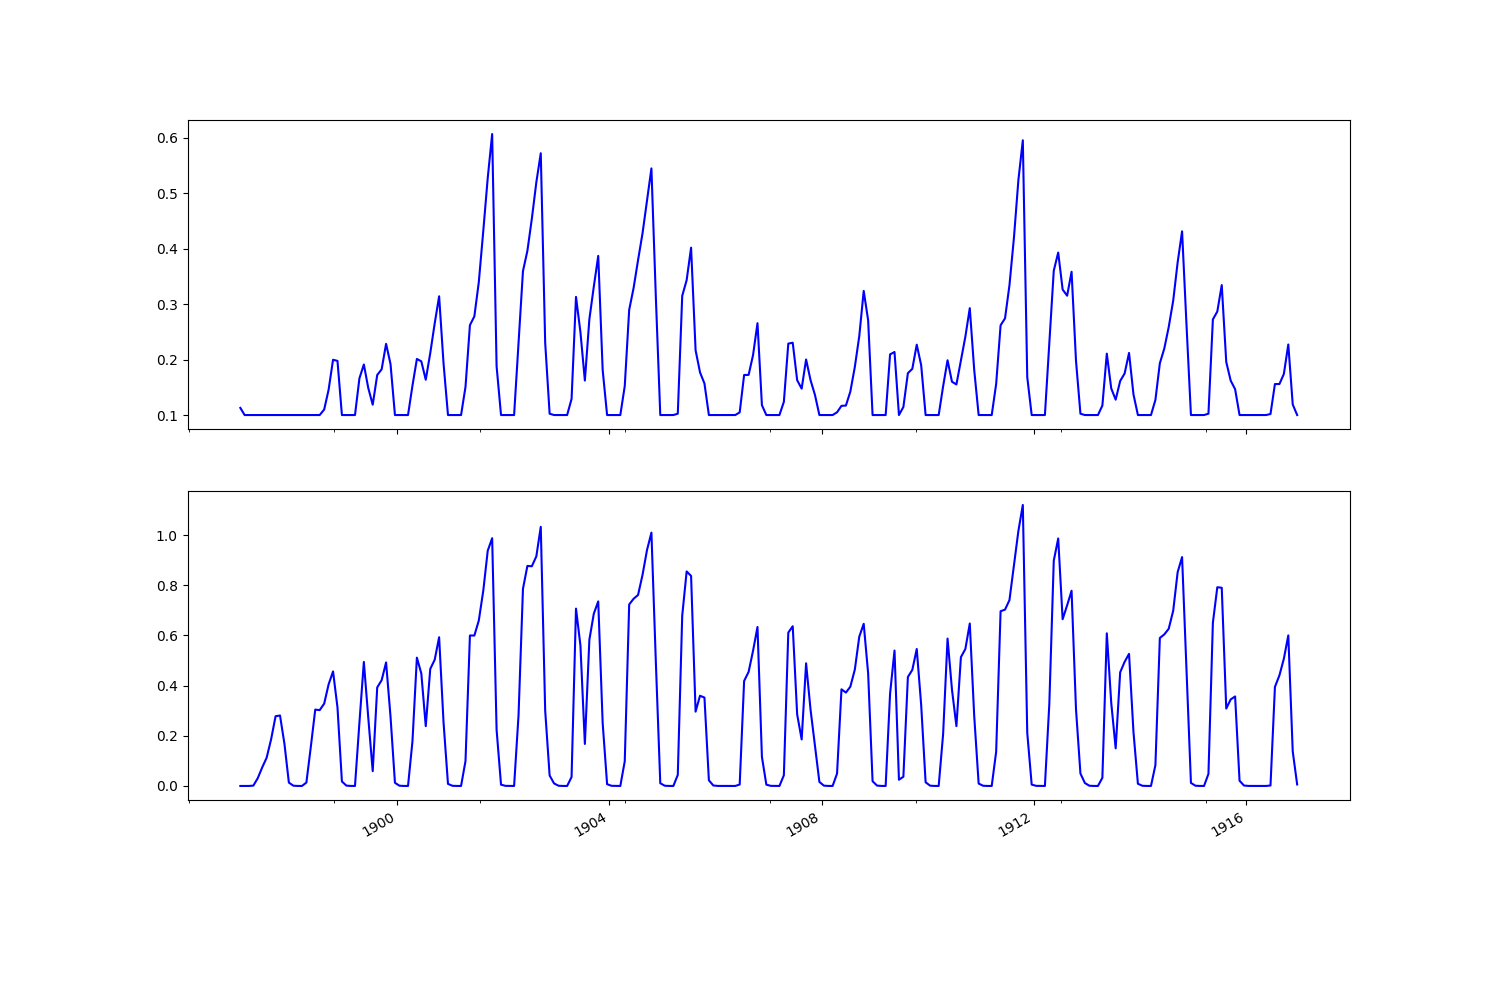

In [9]:
# Plot vegetation height and LAI for both models
fig, ax = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
spinup_veg['height'].plot(ax=ax[0], label='CM Height', color='blue')
spinup_veg['lai'].plot(ax=ax[1], label='CM LAI', color='blue')

### Snow

For many variables, I only care about the last 10 years of the spinup, so I will slice the data accordingly.

In [10]:
spinup_snow = spinup.get_data(['snow_depth', 't_ref'],'land_daily')

In [15]:
Tair = forcing.get_looped_data('Tair', 100)

In [13]:
# Get the starting and ending years for the last 10 years of the spinup
end_date = spinup_snow['snow_depth'].index[-1]
start_date = spinup_snow['snow_depth'].index[-1] - pd.DateOffset(years=10)

print(f'{start_date}:{end_date}')

1907-01-01 12:00:00:1917-01-01 12:00:00


<Axes: >

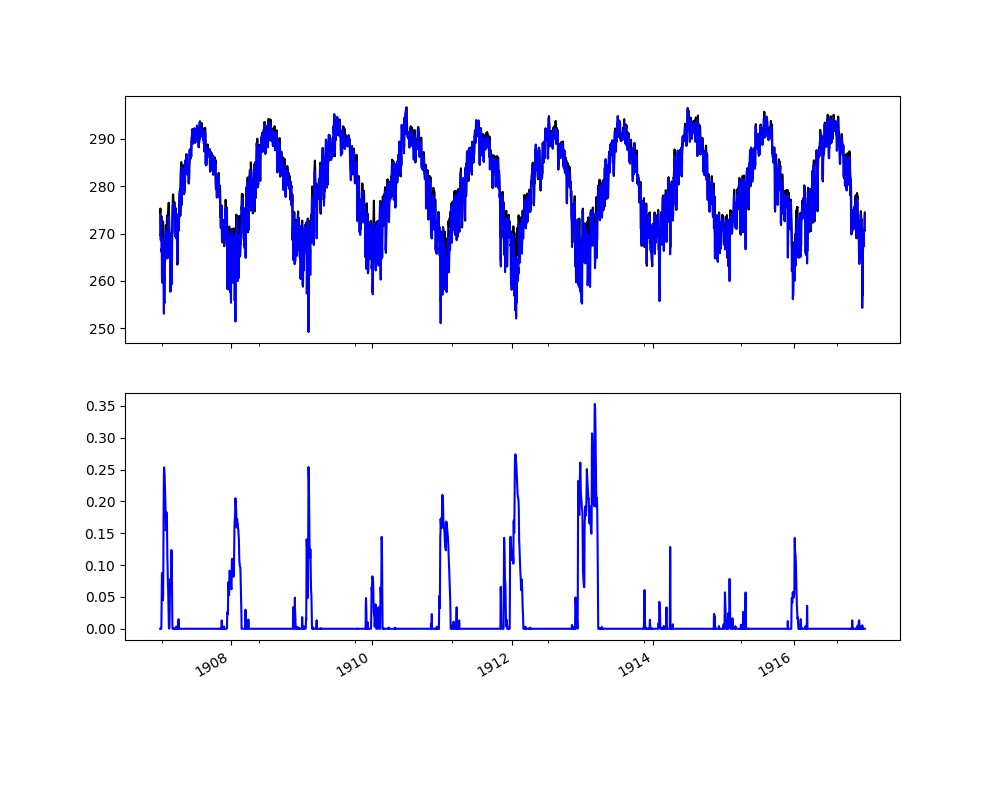

In [16]:
# Plot forcing temperatures and snow depths
fig, ax = plt.subplots(2, 1, figsize=(10, 8), sharex=True)
Tair[start_date:end_date].plot(ax=ax[0], label='Tair', color='black')
spinup_snow.loc[start_date:end_date, 't_ref'].plot(ax=ax[0], label='CM t_ref', color='blue')
spinup_snow.loc[start_date:end_date, 'snow_depth'].plot(ax=ax[1], label='CM Snow Depth', color='blue')

### Soil Temperature

In [17]:
spinup_soil = spinup.get_data(['soil_T'], diag='land_daily')

In [18]:
# Change data in soil dataframes to celsius
spinup_soil = spinup_soil - 273.15

In [19]:
Tair = Tair - 273.15  # Convert Tair to Celsius

<Axes: >

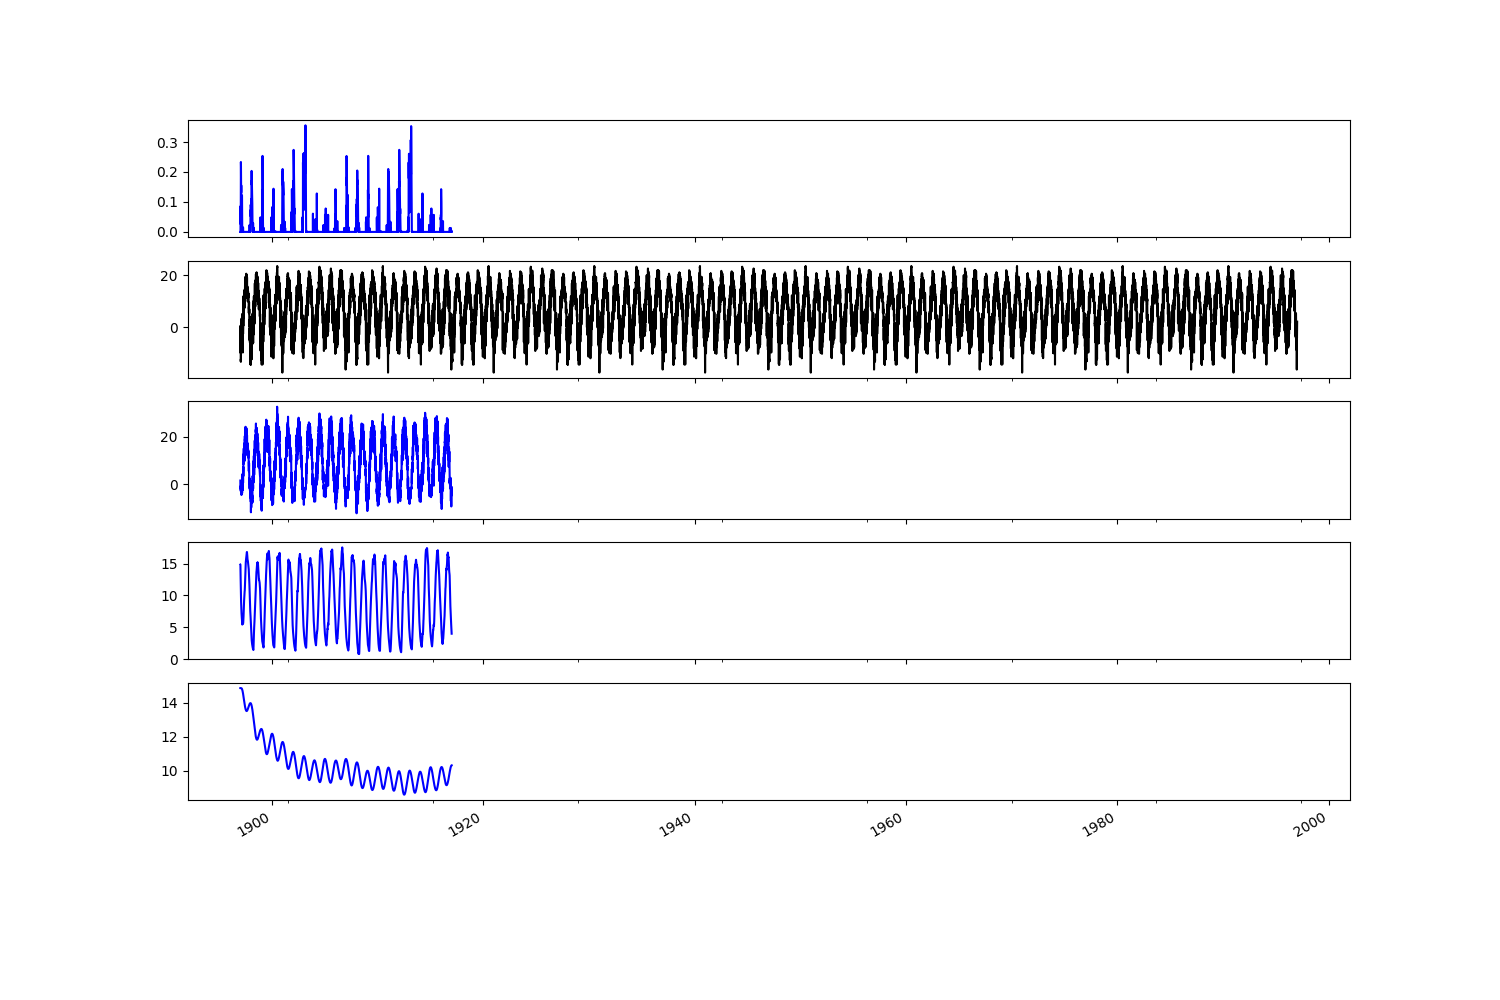

In [20]:
# Plot snow, Tair, and soil temperatures at 0.04, 1.20, 5.50m
fig, ax = plt.subplots(5, 1, figsize=(15, 10), sharex=True)
spinup_snow['snow_depth'].plot(ax=ax[0], label='CM Snow Depth', color='blue')
Tair.plot(ax=ax[1], label='Tair', color='black')
spinup_soil['soil_T 0.04'].plot(ax=ax[2], label='CM Soil T 0.04m', color='blue')
spinup_soil['soil_T 1.20'].plot(ax=ax[3], label='CM Soil T 1.20m', color='blue')
spinup_soil['soil_T 5.50'].plot(ax=ax[4], label='CM Soil T 5.50m', color='blue')

#### Soil liquid/ice water content
These variables are currently in monthly data.

In [ ]:
spinup_soil_water = spinup_spinup.get_data(['soil_liq','soil_ice'], diag='land_month')
gl_soil_water = gl_spinup.get_data(['soil_liq','soil_ice'], diag='land_month')

In [ ]:
Tair_month = Tair.resample('MS').mean()

# Shift index forward 15 days to match the land month data
Tair_month.index = Tair_month.index + pd.DateOffset(days=15)

In [ ]:
# Plot soil water content for both models at depths 0.04, 1.20, 5.50 and 8.75m
fig, ax = plt.subplots(4, 1, figsize=(15, 10), sharex=True)
spinup_soil_water.loc[start_date:end_date, 'soil_liq 0.04'].plot(ax=ax[0], label='CM Soil Liq 0.04m', color='blue')
gl_soil_water.loc[start_date:end_date, 'soil_liq 0.04'].plot(ax=ax[0], label='GL Soil Liq 0.04m', color='orange')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 1.20'].plot(ax=ax[1], label='CM Soil Liq 1.20m', color='blue')
gl_soil_water.loc[start_date:end_date, 'soil_liq 1.20'].plot(ax=ax[1], label='GL Soil Liq 1.20m', color='orange')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 5.50'].plot(ax=ax[2], label='CM Soil Liq 5.50m', color='blue')
gl_soil_water.loc[start_date:end_date, 'soil_liq 5.50'].plot(ax=ax[2], label='GL Soil Liq 5.50m', color='orange')
spinup_soil_water.loc[start_date:end_date, 'soil_liq 8.75'].plot(ax=ax[3], label='CM Soil Liq 8.75m', color='blue')
gl_soil_water.loc[start_date:end_date, 'soil_liq 8.75'].plot(ax=ax[3], label='GL Soil Liq 8.75m', color='orange')